# PCOS SCOPE: Results validation, missing-data handling and explanation stability

**Run this notebook from the `PCOS_SCOPE` project folder** (the same place as `01_dataset_audit.ipynb`).
It is self-contained: it reloads `data/processed/pcos_cleaned.csv` and the saved model, and rebuilds the
exact same 80/20 split (`random_state=42`). It does **not** need any variable from the earlier notebook.

| Part | Question it answers |
|---|---|
| A | Is the deployed model's prediction correct, stable and sensible? |
| B | How well do different missing-value strategies cope with incomplete data? |
| C | Do the *explanations* stay stable when data is missing? (the core of the project title) |
| D | Is the app's "Inconclusive" rule justified by data? |
| E | Save the final model, tables and figures for the report and the app |

Set `QUICK = True` for a 2-minute smoke test, `QUICK = False` for the real run (roughly 10 to 30 minutes depending on your laptop).

In [1]:
# ---------- Cell 1: setup ----------
import json, shutil, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

QUICK = False            # True = fast smoke test
SEED = 42
N_TREES = 100 if QUICK else 300
CV_REPEATS = 1 if QUICK else 2
N_PERM = 5 if QUICK else 20      # label-permutation runs for the leakage check
N_BOOT = 500 if QUICK else 2000  # bootstrap resamples for confidence intervals

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent
REPORTS = ROOT / "reports"; REPORTS.mkdir(exist_ok=True)
MODELS = ROOT / "models"
MODEL_PATH = MODELS / "pcos_scope_random_forest_pipeline.joblib"
BACKUP_PATH = MODELS / "pcos_scope_random_forest_pipeline_v1_baseline.joblib"
META_PATH = MODELS / "pcos_scope_model_metadata.json"
print("Project root:", ROOT)

# ---- data (column names stripped, exactly as in the audit notebook) ----
df = pd.read_csv(ROOT / "data" / "processed" / "pcos_cleaned.csv")
df.columns = df.columns.str.strip()
TARGET = "PCOS (Y/N)"
IDS = ["Sl. No", "Patient File No."]

# Same five groups and same ORDER as the audit notebook (cell 14)
GROUPS = {
    "Physical and metabolic": ["Age (yrs)", "Weight (Kg)", "Height(Cm)", "BMI", "Pulse rate(bpm)",
        "RR (breaths/min)", "Hb(g/dl)", "Hip(inch)", "Waist(inch)", "Waist:Hip Ratio",
        "RBS(mg/dl)", "BP _Systolic (mmHg)", "BP _Diastolic (mmHg)"],
    "Hormonal and biochemical": ["I   beta-HCG(mIU/mL)", "II    beta-HCG(mIU/mL)", "FSH(mIU/mL)",
        "LH(mIU/mL)", "FSH/LH", "TSH (mIU/L)", "AMH(ng/mL)", "PRL(ng/mL)", "Vit D3 (ng/mL)", "PRG(ng/mL)"],
    "Menstrual and reproductive history": ["Cycle(R/I)", "Cycle length(days)", "Marraige Status (Yrs)",
        "Pregnant(Y/N)", "No. of aborptions"],
    "Symptoms and lifestyle": ["Weight gain(Y/N)", "hair growth(Y/N)", "Skin darkening (Y/N)",
        "Hair loss(Y/N)", "Pimples(Y/N)", "Fast food (Y/N)", "Reg.Exercise(Y/N)"],
    "Ovarian measurements": ["Follicle No. (L)", "Follicle No. (R)", "Avg. F size (L) (mm)",
        "Avg. F size (R) (mm)", "Endometrium (mm)"],
}
FEATURES = [f for g in GROUPS.values() for f in g]
CATEGORICAL = ["Cycle(R/I)", "Pregnant(Y/N)", "Weight gain(Y/N)", "hair growth(Y/N)",
               "Skin darkening (Y/N)", "Hair loss(Y/N)", "Pimples(Y/N)", "Fast food (Y/N)", "Reg.Exercise(Y/N)"]
NUMERIC = [f for f in FEATURES if f not in CATEGORICAL]
FEATURE_TO_GROUP = {f: g for g, fs in GROUPS.items() for f in fs}
assert len(FEATURES) == 40 and set(FEATURES) <= set(df.columns), "Feature names do not match the CSV"

X_all = df.drop(columns=IDS + [TARGET])
y_all = df[TARGET].astype(int)
# identical split to the audit notebook (split depends only on n, y and the seed)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
X_train, X_test = X_train[FEATURES], X_test[FEATURES]
X_full = X_all[FEATURES].reset_index(drop=True)
y_full = y_all.reset_index(drop=True)
print(f"Train {X_train.shape} | Test {X_test.shape} | PCOS rate {y_all.mean():.1%}")

Project root: C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE
Train (432, 40) | Test (109, 40) | PCOS rate 32.7%


In [2]:
# ---------- Cell 2: shared helpers (metrics, masking, derived-value filling, model factory) ----------
def metrics(y_true, prob, thr=0.5):
    y_true = np.asarray(y_true)
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(
        Accuracy=(tp + tn) / len(y_true),
        Sensitivity=tp / (tp + fn) if tp + fn else np.nan,
        Specificity=tn / (tn + fp) if tn + fp else np.nan,
        ROC_AUC=roc_auc_score(y_true, prob),
        TN=tn, FP=fp, FN=fn, TP=tp)


def fill_derived(X):
    """KNOWLEDGE-BASED imputation. Your audit proved these three columns are exact formulas of other columns
    (mean |difference| 0.02 for BMI, ~0 for FSH/LH and Waist:Hip). If the ingredients are present, calculate
    the value instead of letting a median stand in for it. Only fills cells that are missing."""
    X = X.copy()
    w, h = X["Weight (Kg)"], X["Height(Cm)"]
    m = X["BMI"].isna() & w.notna() & h.notna() & (h > 0)
    X.loc[m, "BMI"] = w[m] / (h[m] / 100) ** 2
    wa, hi = X["Waist(inch)"], X["Hip(inch)"]
    m = X["Waist:Hip Ratio"].isna() & wa.notna() & hi.notna() & (hi > 0)
    X.loc[m, "Waist:Hip Ratio"] = wa[m] / hi[m]
    f, l = X["FSH(mIU/mL)"], X["LH(mIU/mL)"]
    m = X["FSH/LH"].isna() & f.notna() & l.notna() & (l > 0)
    X.loc[m, "FSH/LH"] = f[m] / l[m]
    return X


# ---- missingness generators (all take a DataFrame + rng and return a masked copy) ----
def mask_cells(X, rate, rng):                 # MCAR: any cell can vanish
    return X.mask(rng.random(X.shape) < rate)

def mask_groups(X, group_names):              # whole clinical group unavailable for every patient
    X = X.copy()
    for g in group_names:
        X[GROUPS[g]] = np.nan
    return X

def mask_random_groups(X, p, rng, cell_rate=0.0):   # each patient lacks each group independently w.p. p
    X = X.copy()
    for g, cols in GROUPS.items():
        rows = rng.random(len(X)) < p
        X.loc[rows, cols] = np.nan
    if cell_rate:
        X = mask_cells(X, cell_rate, rng)
    return X


def augment(X, y, rng):
    """Training-time masking: the original rows plus masked copies, so the model and its imputer SEE
    incomplete records during training (the training data has only 3 missing cells in total)."""
    parts, ys = [X], [y]
    for r in (0.10, 0.20, 0.30):
        parts.append(mask_cells(X, r, rng)); ys.append(y)
    parts.append(mask_random_groups(X, 0.25, rng)); ys.append(y)
    return pd.concat(parts, ignore_index=True), pd.concat(ys, ignore_index=True)


# ---- model factory. Step names ("preprocessor", "classifier") match the deployed app pipeline ----
def make_model(kind):
    cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
    if kind in ("A", "B", "E"):
        num = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    elif kind == "C":
        num = Pipeline([("scaler", StandardScaler()), ("imputer", KNNImputer(n_neighbors=5))])
    elif kind == "D":
        num = Pipeline([("imputer", IterativeImputer(max_iter=10, random_state=SEED))])
    if kind == "F":      # gradient boosting that handles NaN natively (no imputer at all)
        pre = ColumnTransformer([("all", "passthrough", FEATURES)])
        try:
            clf = HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.05,
                                                 max_iter=200, random_state=SEED)
        except TypeError:   # older scikit-learn without class_weight
            clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, random_state=SEED)
    else:
        pre = ColumnTransformer([("numeric", num, NUMERIC), ("categorical", cat, CATEGORICAL)],
                                remainder="drop")
        clf = RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced", random_state=SEED)
    return Pipeline([("preprocessor", pre), ("classifier", clf)])


STRATS = {
    "A": dict(name="A. Median imputation (current app)", fill=False, aug=False),
    "B": dict(name="B. Derived values + median",           fill=True,  aug=False),
    "C": dict(name="C. Derived values + KNN imputer",      fill=True,  aug=False),
    "D": dict(name="D. Derived values + iterative imputer", fill=True, aug=False),
    "E": dict(name="E. Derived + median + train-time masking", fill=True, aug=True),
    "F": dict(name="F. Gradient boosting (native NaN) + train-time masking", fill=True, aug=True),
}
prep = lambda X, fill: fill_derived(X) if fill else X

SCENARIOS = {
    "Complete": lambda X, r: X.copy(),
    "Cells 10%": lambda X, r: mask_cells(X, .10, r),
    "Cells 20%": lambda X, r: mask_cells(X, .20, r),
    "Cells 30%": lambda X, r: mask_cells(X, .30, r),
    "Cells 40%": lambda X, r: mask_cells(X, .40, r),
    "Cells 50%": lambda X, r: mask_cells(X, .50, r),
    "No physical":   lambda X, r: mask_groups(X, ["Physical and metabolic"]),
    "No hormonal":   lambda X, r: mask_groups(X, ["Hormonal and biochemical"]),
    "No menstrual":  lambda X, r: mask_groups(X, ["Menstrual and reproductive history"]),
    "No symptoms":   lambda X, r: mask_groups(X, ["Symptoms and lifestyle"]),
    "No ovarian":    lambda X, r: mask_groups(X, ["Ovarian measurements"]),
    "No hormonal + ovarian (no lab, no scan)": lambda X, r: mask_groups(
        X, ["Hormonal and biochemical", "Ovarian measurements"]),
    "Random groups missing (40% each)": lambda X, r: mask_random_groups(X, .40, r),
}

# quick self-test of the helpers
_t = X_train.head(5).copy(); _t.loc[_t.index[0], ["BMI", "FSH/LH"]] = np.nan
_f = fill_derived(_t)
assert _f["BMI"].notna().all() and _f["FSH/LH"].notna().all()
print("Helpers OK. Derived BMI restored for row 0:", round(float(_f['BMI'].iloc[0]), 2),
      "| original:", round(float(X_train.head(5)['BMI'].iloc[0]), 2))

Helpers OK. Derived BMI restored for row 0: 23.16 | original: 23.16


## Part A: Is the deployed model's prediction correct?
A1 reproduces your saved model's numbers, A2 gives honest confidence intervals, A3 checks calibration,
A4 proves there is no leakage, A5 checks the model behaves in a clinically sensible direction,
A6 chooses the decision threshold without touching the test set.

In [3]:
# ---------- A1 + A2: reproduce the saved model's test result and add 95% bootstrap CIs ----------
saved = joblib.load(BACKUP_PATH if BACKUP_PATH.exists() else MODEL_PATH)   # always the ORIGINAL baseline
p_saved = saved.predict_proba(X_test)[:, list(saved.classes_).index(1)]
m_saved = metrics(y_test, p_saved)

print("A1. REPRODUCTION CHECK against your notebook (E3 'All five main groups' = the deployed 40-feature model):")
print("    expected TN=69, FP=4, FN=6, TP=30, accuracy 0.9083, ROC-AUC 0.9425")
print({k: (round(v, 4) if isinstance(v, float) else int(v)) for k, v in m_saved.items()})
match = ((m_saved["TN"], m_saved["FP"], m_saved["FN"], m_saved["TP"]) == (69, 4, 6, 30)
         and abs(m_saved["ROC_AUC"] - 0.9425) < 0.002)
print("MATCHES your notebook:", match,
      "" if match else "  <-- differs: check scikit-learn version / that the saved model is the latest one")

rng = np.random.default_rng(SEED)
yt = np.asarray(y_test); boots = []
for _ in range(N_BOOT):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max():
        continue
    boots.append(metrics(yt[i], p_saved[i]))
boot = pd.DataFrame(boots)[["Accuracy", "Sensitivity", "Specificity", "ROC_AUC"]]
ci = pd.DataFrame({"Point estimate": [m_saved[c] for c in boot.columns],
                   "CI 2.5%": boot.quantile(.025).values, "CI 97.5%": boot.quantile(.975).values},
                  index=boot.columns).round(3)
print("\nA2. 95% bootstrap confidence intervals (109 test patients, only 36 PCOS-positive):")
display(ci)
print("Say this in the review: sensitivity rests on 36 positive patients, so its interval is wide;"
      " a single split cannot support finer claims.")

A1. REPRODUCTION CHECK against your notebook (E3 'All five main groups' = the deployed 40-feature model):
    expected TN=69, FP=4, FN=6, TP=30, accuracy 0.9083, ROC-AUC 0.9425
{'Accuracy': np.float64(0.9083), 'Sensitivity': np.float64(0.8333), 'Specificity': np.float64(0.9452), 'ROC_AUC': 0.9425, 'TN': 69, 'FP': 4, 'FN': 6, 'TP': 30}
MATCHES your notebook: True 

A2. 95% bootstrap confidence intervals (109 test patients, only 36 PCOS-positive):


,Point estimate,CI 2.5%,CI 97.5%
Accuracy,0.908,0.853,0.963
Sensitivity,0.833,0.703,0.943
Specificity,0.945,0.886,0.987
ROC_AUC,0.943,0.882,0.988


Say this in the review: sensitivity rests on 36 positive patients, so its interval is wide; a single split cannot support finer claims.


Out-of-fold (all 541 patients): ROC-AUC 0.960 | PR-AUC 0.933 | Brier 0.085 (Brier of always predicting the base rate: 0.220)


,Patients,Mean_score,Actual_PCOS_rate
bin,,,
"(-0.001, 0.1]",151,0.053,0.007
"(0.1, 0.3]",134,0.195,0.045
"(0.3, 0.5]",83,0.399,0.277
"(0.5, 0.7]",63,0.604,0.651
"(0.7, 0.9]",77,0.809,0.948
"(0.9, 1.0]",33,0.941,1.000


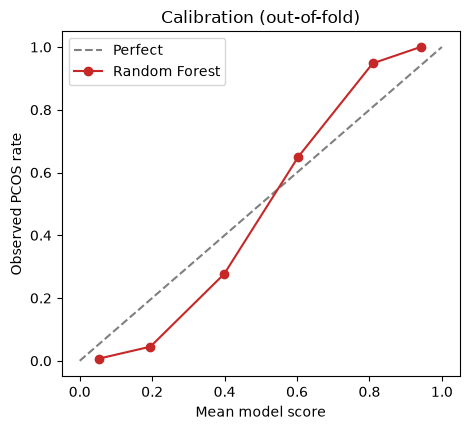

Why it matters: the app shows the score as a percentage. Forest scores are NOT calibrated probabilities, which is why the app calls it a 'model score'. Keep that wording.


In [4]:
# ---------- A3: out-of-fold calibration (is a score of 0.8 really ~80% PCOS?) ----------
oof = cross_val_predict(make_model("A"), X_full, y_full,
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"Out-of-fold (all 541 patients): ROC-AUC {roc_auc_score(y_full, oof):.3f} | "
      f"PR-AUC {average_precision_score(y_full, oof):.3f} | Brier {brier_score_loss(y_full, oof):.3f} "
      f"(Brier of always predicting the base rate: {y_full.mean()*(1-y_full.mean()):.3f})")
bins = pd.cut(oof, [0, .1, .3, .5, .7, .9, 1.0], include_lowest=True)
calib = pd.DataFrame({"score": oof, "actual": y_full, "bin": bins}).groupby("bin", observed=True).agg(
    Patients=("actual", "size"), Mean_score=("score", "mean"), Actual_PCOS_rate=("actual", "mean")).round(3)
display(calib)
plt.figure(figsize=(4.8, 4.4))
plt.plot([0, 1], [0, 1], "--", color="grey", label="Perfect")
plt.plot(calib["Mean_score"], calib["Actual_PCOS_rate"], "o-", color="#C62828", label="Random Forest")
plt.xlabel("Mean model score"); plt.ylabel("Observed PCOS rate"); plt.title("Calibration (out-of-fold)")
plt.legend(); plt.tight_layout(); plt.savefig(REPORTS / "A3_calibration.png", dpi=200); plt.show()
print("Why it matters: the app shows the score as a percentage. Forest scores are NOT calibrated"
      " probabilities, which is why the app calls it a 'model score'. Keep that wording.")

In [5]:
# ---------- A4: leakage / sanity test with shuffled labels ----------
real = cross_val_score(make_model("A"), X_full, y_full, scoring="roc_auc",
                       cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).mean()
perm_scores = []
rng = np.random.default_rng(SEED)
for i in range(N_PERM):
    y_shuf = pd.Series(rng.permutation(y_full.values))
    perm_scores.append(cross_val_score(make_model("A"), X_full, y_shuf, scoring="roc_auc",
                                       cv=StratifiedKFold(5, shuffle=True, random_state=i)).mean())
print(f"Real labels   : CV ROC-AUC = {real:.3f}")
print(f"Shuffled labels ({N_PERM} runs): mean = {np.mean(perm_scores):.3f}, max = {np.max(perm_scores):.3f}")
print("PASS: pipeline does not leak (shuffled labels give ~0.5)" if np.max(perm_scores) < 0.62
      else "WARNING: shuffled labels score high; investigate leakage")

Real labels   : CV ROC-AUC = 0.960
Shuffled labels (20 runs): mean = 0.501, max = 0.559
PASS: pipeline does not leak (shuffled labels give ~0.5)


In [6]:
# ---------- A5: does the model move in a clinically sensible direction? ----------
base_neg = X_train[y_train == 0].median(numeric_only=True)
score = lambda row: float(saved.predict_proba(pd.DataFrame([row], columns=FEATURES))[0, 1])
print(f"Mean model score on TEST patients who truly have PCOS : {p_saved[np.asarray(y_test) == 1].mean():.2f}")
print(f"Mean model score on TEST patients who truly do NOT    : {p_saved[np.asarray(y_test) == 0].mean():.2f}")

# ---- error analysis: every mistake at threshold 0.5, with the clinical values a reviewer will ask about ----
key_cols = ["Follicle No. (R)", "Follicle No. (L)", "hair growth(Y/N)", "Weight gain(Y/N)",
            "Skin darkening (Y/N)", "Cycle(R/I)", "AMH(ng/mL)", "FSH/LH"]
ea = X_test[key_cols].copy(); ea["Actual"] = np.asarray(y_test); ea["Score"] = p_saved
ea["Result"] = np.where((ea.Score >= .5) == (ea.Actual == 1), "correct",
                        np.where(ea.Actual == 1, "MISSED PCOS (FN)", "FALSE ALARM (FP)"))
print("\nThe model's mistakes on the test set (explain these if asked):")
display(ea[ea.Result != "correct"].sort_values("Score").round(2))
print("Check this table: if the missed cases (FN) have few follicles and no visible symptoms, the model is not"
      " broken; those patients simply look like non-PCOS on the features it relies on. Say exactly that.")

print("\nWhat-if check: start from the typical NON-PCOS profile and change one thing at a time.")
what_if = []
for fval in (2, 4, 6, 8, 10, 12, 15, 20):
    r = base_neg[FEATURES].copy(); r["Follicle No. (R)"] = fval; r["Follicle No. (L)"] = fval
    what_if.append(("Follicle count (both ovaries)", fval, score(r)))
for feat in ("hair growth(Y/N)", "Weight gain(Y/N)", "Skin darkening (Y/N)"):
    for v in (0, 1):
        r = base_neg[FEATURES].copy(); r[feat] = v
        what_if.append((feat, v, score(r)))
display(pd.DataFrame(what_if, columns=["Feature changed (rest = non-PCOS median)", "Value", "Model score"]).round(3))
print("Expected: score rises with follicle count and with the symptoms. If it does, the model has learned"
      " the clinically expected direction.")

Mean model score on TEST patients who truly have PCOS : 0.71
Mean model score on TEST patients who truly do NOT    : 0.21

The model's mistakes on the test set (explain these if asked):


,Follicle No. (R),Follicle No. (L),hair growth(Y/N),Weight gain(Y/N),Skin darkening (Y/N),Cycle(R/I),AMH(ng/mL),FSH/LH,Actual,Score,Result
444,1,1,0,0,0,2,16.9,2.23,1,0.07,MISSED PCOS (FN)
455,7,6,0,0,0,2,7.7,0.00,1,0.18,MISSED PCOS (FN)
227,3,1,1,1,1,2,0.2,2.10,1,0.29,MISSED PCOS (FN)
533,10,8,0,0,0,4,19.6,0.80,1,0.40,MISSED PCOS (FN)
276,5,6,0,1,0,4,1.8,1.12,1,0.42,MISSED PCOS (FN)
132,3,3,1,1,1,2,8.8,1.11,1,0.43,MISSED PCOS (FN)
521,10,8,1,0,0,2,2.5,2.84,0,0.51,FALSE ALARM (FP)
111,4,5,1,0,1,4,1.6,2.85,0,0.56,FALSE ALARM (FP)
118,9,7,0,0,1,2,5.0,3.18,0,0.56,FALSE ALARM (FP)
377,7,8,0,1,0,4,9.1,5.59,0,0.74,FALSE ALARM (FP)


Check this table: if the missed cases (FN) have few follicles and no visible symptoms, the model is not broken; those patients simply look like non-PCOS on the features it relies on. Say exactly that.

What-if check: start from the typical NON-PCOS profile and change one thing at a time.


,Feature changed (rest = non-PCOS median),Value,Model score
0,Follicle count (both ovaries),2,0.000
1,Follicle count (both ovaries),4,0.000
2,Follicle count (both ovaries),6,0.003
3,Follicle count (both ovaries),8,0.100
4,Follicle count (both ovaries),10,0.283
5,Follicle count (both ovaries),12,0.567
6,Follicle count (both ovaries),15,0.657
7,Follicle count (both ovaries),20,0.660
8,hair growth(Y/N),0,0.000
9,hair growth(Y/N),1,0.113


Expected: score rises with follicle count and with the symptoms. If it does, the model has learned the clinically expected direction.


In [7]:
# ---------- A6: pick the threshold from TRAINING data only, then test it once ----------
oof_tr = cross_val_predict(make_model("A"), X_train, y_train,
                           cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
grid = np.round(np.arange(0.20, 0.71, 0.05), 2)
tr_tab = pd.DataFrame([{"Threshold": t, **{k: v for k, v in metrics(y_train, oof_tr, t).items()
                        if k in ("Accuracy", "Sensitivity", "Specificity")}} for t in grid]).round(3)
display(tr_tab)
TARGET_SENS = 0.90       # a screening tool should rarely miss PCOS; change if your guide prefers otherwise
ok = tr_tab[tr_tab["Sensitivity"] >= TARGET_SENS]
if len(ok):
    thr_cv = float(ok.sort_values("Specificity", ascending=False).iloc[0]["Threshold"])
    print(f"Screening rule: highest threshold whose CV sensitivity is still >= {TARGET_SENS}  ->  {thr_cv}")
else:                    # fall back to Youden's J (sensitivity + specificity - 1)
    tr_tab["J"] = tr_tab["Sensitivity"] + tr_tab["Specificity"] - 1
    thr_cv = float(tr_tab.sort_values("J", ascending=False).iloc[0]["Threshold"])
    print(f"No threshold reaches CV sensitivity {TARGET_SENS}; using Youden's J  ->  {thr_cv}")
for t in sorted({0.5, thr_cv}):
    mt = metrics(y_test, p_saved, t)
    print(f"  Test set at threshold {t}: acc {mt['Accuracy']:.3f}  sens {mt['Sensitivity']:.3f}  "
          f"spec {mt['Specificity']:.3f}  (FN={mt['FN']}, FP={mt['FP']})")
print("Defence for the review: in your notebook, 0.6 looked best on the TEST set, but choosing it there is"
      " optimistic. This threshold came from training folds only. The app still uses 0.5; this is reported as an option.")

,Threshold,Accuracy,Sensitivity,Specificity
0,0.20,0.729,0.986,0.605
1,0.25,0.769,0.979,0.667
2,0.30,0.808,0.957,0.735
3,0.35,0.845,0.943,0.797
4,0.40,0.868,0.901,0.852
5,0.45,0.889,0.879,0.893
6,0.50,0.896,0.844,0.921
7,0.55,0.896,0.794,0.945
8,0.60,0.896,0.759,0.962
9,0.65,0.877,0.667,0.979


Screening rule: highest threshold whose CV sensitivity is still >= 0.9  ->  0.4
  Test set at threshold 0.4: acc 0.881  sens 0.917  spec 0.863  (FN=3, FP=10)
  Test set at threshold 0.5: acc 0.908  sens 0.833  spec 0.945  (FN=6, FP=4)
Defence for the review: in your notebook, 0.6 looked best on the TEST set, but choosing it there is optimistic. This threshold came from training folds only. The app still uses 0.5; this is reported as an option.


## Part B: How is missing data handled? Six strategies, compared fairly

**What is wrong with the current handling (say this yourself before a reviewer does):**
1. The training data has only **3 missing cells in 541 x 41**, so the model and its imputers have never seen
   incomplete records. Median imputation then makes every missing value look like the "average patient".
2. BMI, Waist:Hip ratio and FSH/LH are exact formulas of other columns (your own audit), yet the app lets a
   median stand in for them even when the ingredients were typed in.
3. E5 ("missing group") **retrains** a smaller model. The app instead feeds the **same full model** a record
   with a hole in it. Those are different situations; the app's "Data Lab" numbers described the first.

**What is tested here** (5-fold CV x repeats on all 541 patients, identical masked data for every strategy):
A current | B + derived-value filling | C + KNN | D + iterative imputer | E + training-time masking | F gradient boosting with native NaN handling.

In [8]:
# ---------- B1: run the comparison ----------
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=CV_REPEATS, random_state=SEED)
rows, fitted, fold_data = [], {}, {}
for fold_id, (tr, te) in enumerate(cv.split(X_full, y_full)):
    Xtr, ytr, Xte, yte = X_full.iloc[tr], y_full.iloc[tr], X_full.iloc[te], y_full.iloc[te]
    Xaug, yaug = augment(Xtr, ytr, np.random.default_rng(SEED + fold_id))
    for k, s in STRATS.items():
        Xa, ya = (Xaug, yaug) if s["aug"] else (Xtr, ytr)
        fitted[(fold_id, k)] = make_model(k).fit(prep(Xa, s["fill"]), ya)
    fold_data[fold_id] = (Xte, yte)
    for si, (sc, fn) in enumerate(SCENARIOS.items()):
        Xm = fn(Xte, np.random.default_rng(10_000 + fold_id * 100 + si))   # same masked data for all strategies
        for k, s in STRATS.items():
            p = fitted[(fold_id, k)].predict_proba(prep(Xm, s["fill"]))[:, 1]
            rows.append(dict(Fold=fold_id, Strategy=k, Scenario=sc, **metrics(yte.values, p)))
    print(f"fold {fold_id + 1}/{cv.get_n_splits()} done", end=" | ")
res = pd.DataFrame(rows)
res.to_csv(REPORTS / "B_all_strategy_fold_results.csv", index=False)

summ = res.groupby(["Scenario", "Strategy"])[["Accuracy", "Sensitivity", "Specificity", "ROC_AUC"]].mean().reset_index()
summ.assign(Strategy_name=summ.Strategy.map(lambda k: STRATS[k]["name"])).round(4).to_csv(
    REPORTS / "B_strategy_summary.csv", index=False)   # read by the app's Data Lab
order = list(SCENARIOS)
auc_tab = summ.pivot(index="Scenario", columns="Strategy", values="ROC_AUC").loc[order]
sens_tab = summ.pivot(index="Scenario", columns="Strategy", values="Sensitivity").loc[order]
acc_tab = summ.pivot(index="Scenario", columns="Strategy", values="Accuracy").loc[order]
print("\n\nROC-AUC by scenario (rows) and strategy (columns):"); display(auc_tab.round(3))
print("Sensitivity (share of PCOS patients caught):"); display(sens_tab.round(3))
print("Accuracy:"); display(acc_tab.round(3))
print({k: v["name"] for k, v in STRATS.items()})

fold 1/10 done | fold 2/10 done | fold 3/10 done | fold 4/10 done | fold 5/10 done | fold 6/10 done | fold 7/10 done | fold 8/10 done | fold 9/10 done | fold 10/10 done | 

ROC-AUC by scenario (rows) and strategy (columns):


Strategy,A,B,C,D,E,F
Scenario,,,,,,
Complete,0.960,0.960,0.960,0.960,0.957,0.955
Cells 10%,0.951,0.950,0.952,0.954,0.951,0.945
Cells 20%,0.942,0.941,0.942,0.944,0.946,0.940
Cells 30%,0.918,0.917,0.920,0.922,0.922,0.917
Cells 40%,0.890,0.890,0.896,0.902,0.899,0.901
Cells 50%,0.893,0.894,0.899,0.899,0.899,0.899
No physical,0.960,0.960,0.961,0.960,0.958,0.955
No hormonal,0.958,0.958,0.956,0.957,0.955,0.947
No menstrual,0.953,0.953,0.955,0.953,0.951,0.948


Sensitivity (share of PCOS patients caught):


Strategy,A,B,C,D,E,F
Scenario,,,,,,
Complete,0.848,0.848,0.850,0.848,0.882,0.817
Cells 10%,0.800,0.800,0.820,0.828,0.868,0.806
Cells 20%,0.763,0.754,0.786,0.797,0.839,0.791
Cells 30%,0.621,0.618,0.706,0.701,0.786,0.741
Cells 40%,0.505,0.514,0.619,0.616,0.712,0.706
Cells 50%,0.443,0.449,0.571,0.557,0.676,0.723
No physical,0.853,0.853,0.847,0.853,0.913,0.820
No hormonal,0.831,0.831,0.851,0.819,0.893,0.833
No menstrual,0.822,0.822,0.831,0.822,0.862,0.808


Accuracy:


Strategy,A,B,C,D,E,F
Scenario,,,,,,
Complete,0.901,0.901,0.903,0.901,0.886,0.897
Cells 10%,0.892,0.892,0.898,0.896,0.888,0.892
Cells 20%,0.890,0.887,0.887,0.888,0.891,0.886
Cells 30%,0.848,0.847,0.865,0.863,0.872,0.855
Cells 40%,0.814,0.816,0.834,0.835,0.848,0.846
Cells 50%,0.808,0.810,0.830,0.834,0.844,0.842
No physical,0.898,0.898,0.901,0.899,0.895,0.895
No hormonal,0.904,0.904,0.904,0.897,0.882,0.897
No menstrual,0.905,0.905,0.908,0.905,0.893,0.889


{'A': 'A. Median imputation (current app)', 'B': 'B. Derived values + median', 'C': 'C. Derived values + KNN imputer', 'D': 'D. Derived values + iterative imputer', 'E': 'E. Derived + median + train-time masking', 'F': 'F. Gradient boosting (native NaN) + train-time masking'}



Paired ROC-AUC difference, strategy B minus A (positive = B better), over 10 folds:


,mean_diff,sd,folds_better
Scenario,,,
Complete,0.0000,0.0000,0
Cells 10%,-0.0003,0.0007,3
Cells 20%,-0.0006,0.0018,3
Cells 30%,-0.0002,0.0013,4
Cells 40%,0.0003,0.0022,4
Cells 50%,0.0009,0.0036,4
No physical,0.0000,0.0000,0
No hormonal,0.0000,0.0000,0
No menstrual,0.0000,0.0000,0



Paired ROC-AUC difference, strategy E minus A (positive = E better), over 10 folds:


,mean_diff,sd,folds_better
Scenario,,,
Complete,-0.0027,0.0047,2
Cells 10%,-0.0000,0.0108,3
Cells 20%,0.0040,0.0122,4
Cells 30%,0.0043,0.0108,8
Cells 40%,0.0095,0.0148,8
Cells 50%,0.0062,0.0118,5
No physical,-0.0027,0.0052,3
No hormonal,-0.0024,0.0065,3
No menstrual,-0.0023,0.0045,3


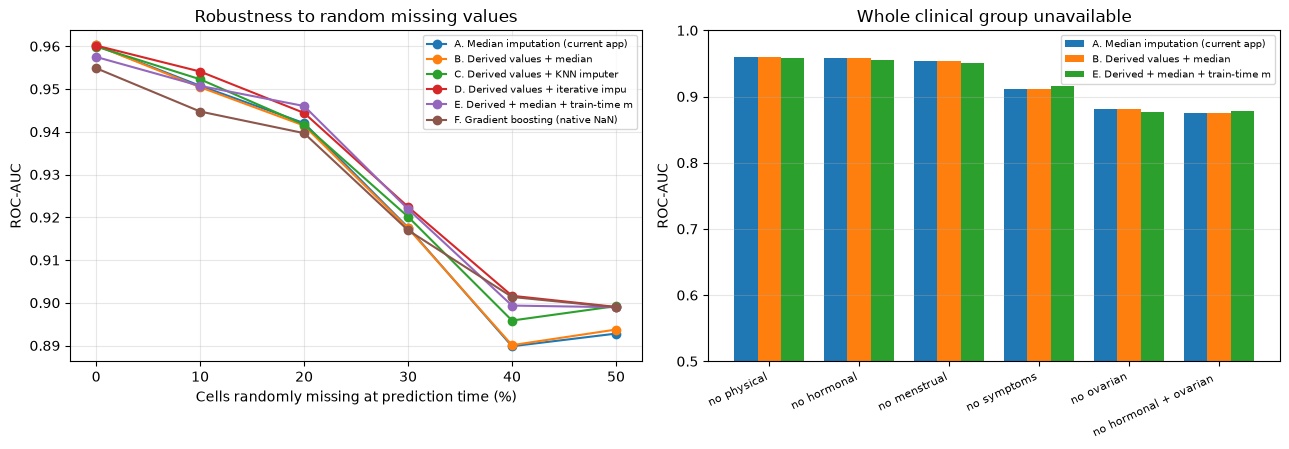

In [9]:
# ---------- B2: paired differences vs the current app, and the figures ----------
def paired(a, b, metric="ROC_AUC"):
    pa = res[res.Strategy == a].pivot(index="Fold", columns="Scenario", values=metric)
    pb = res[res.Strategy == b].pivot(index="Fold", columns="Scenario", values=metric)
    d = (pb - pa)[order]
    return pd.DataFrame({"mean_diff": d.mean(), "sd": d.std(), "folds_better": (d > 0).sum()})

for k in ("B", "E"):
    print(f"\nPaired ROC-AUC difference, strategy {k} minus A (positive = {k} better), over {res.Fold.nunique()} folds:")
    display(paired("A", k).round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
cells = ["Complete", "Cells 10%", "Cells 20%", "Cells 30%", "Cells 40%", "Cells 50%"]
for k in STRATS:
    ax[0].plot([0, 10, 20, 30, 40, 50], auc_tab.loc[cells, k].values, "o-", label=STRATS[k]["name"][:34])
ax[0].set_xlabel("Cells randomly missing at prediction time (%)"); ax[0].set_ylabel("ROC-AUC")
ax[0].set_title("Robustness to random missing values"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
grp = [s for s in order if s.startswith("No ")]
w = 0.26
for j, k in enumerate(("A", "B", "E")):
    ax[1].bar(np.arange(len(grp)) + j * w, auc_tab.loc[grp, k].values, w, label=STRATS[k]["name"][:34])
ax[1].set_xticks(np.arange(len(grp)) + w); ax[1].set_xticklabels([g.replace("No ", "no ")[:22] for g in grp],
                                                                  rotation=25, ha="right", fontsize=8)
ax[1].set_ylim(0.5, 1.0); ax[1].set_ylabel("ROC-AUC"); ax[1].set_title("Whole clinical group unavailable")
ax[1].legend(fontsize=7); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(REPORTS / "B_strategy_comparison.png", dpi=200); plt.show()

In [10]:
# ---------- B3: which strategy should the app use? (transparent, rule-based) ----------
miss_sc = [s for s in order if s != "Complete"]
mean_miss_auc = auc_tab.loc[miss_sc].mean()
print("Mean ROC-AUC across ALL missing-data scenarios:"); print(mean_miss_auc.round(4).to_string())
cplt = auc_tab.loc["Complete"]; csens = sens_tab.loc["Complete"]
robust_ok = (mean_miss_auc["E"] - mean_miss_auc["B"] >= 0.005
             and cplt["B"] - cplt["E"] <= 0.01 and csens["B"] - csens["E"] <= 0.03)
DEPLOY = "E" if robust_ok else "B"
print(f"\nDecision rule: deploy E (train-time masking) only if it beats B by >= 0.005 mean AUC under missingness"
      f" AND loses <= 0.01 AUC / 0.03 sensitivity on complete data.")
print(f"-> Strategy to deploy: {DEPLOY}  ({STRATS[DEPLOY]['name']})")
print("   (B keeps your saved model file unchanged; the app only adds derived-value filling.)")
# DEPLOY = "B"   # <- uncomment to override the automatic choice

Mean ROC-AUC across ALL missing-data scenarios:
Strategy
A    0.9159
B    0.9159
C    0.9136
D    0.9184
E    0.9190
F    0.9165

Decision rule: deploy E (train-time masking) only if it beats B by >= 0.005 mean AUC under missingness AND loses <= 0.01 AUC / 0.03 sensitivity on complete data.
-> Strategy to deploy: B  (B. Derived values + median)
   (B keeps your saved model file unchanged; the app only adds derived-value filling.)


## Part C: Do the *explanations* survive missing data?
Your title is about **explainable** ML under incomplete data, but E7 only varied the *training subset*.
The planned comparison "explanations across complete and incomplete conditions" was never run. This is it.

For each scenario we recompute permutation importance on the masked test set and compare it with the
complete-data explanation: Spearman rank correlation over the 10 features that matter most when data is complete, top-5 overlap, whether the #1 feature is kept, and how much
importance each **clinical group** carries (group importance permutes a whole group together, which fixes the
L/R follicle problem where correlated features split the credit).

In [11]:
# ---------- C1: build the two models on the train split, compute explanation stability ----------
Xaug_tr, yaug_tr = augment(X_train, y_train, np.random.default_rng(SEED))
final_models = {
    "A": (make_model("A").fit(X_train, y_train), False),
    "E": (make_model("E").fit(fill_derived(Xaug_tr), yaug_tr), True),
}
N_DRAWS = 2 if QUICK else 4
N_REP = 3 if QUICK else 5

def feat_imp(model, X, y, fill, seed):
    r = permutation_importance(model, prep(X, fill), y, scoring="roc_auc", n_repeats=N_REP,
                               random_state=seed, n_jobs=-1)
    return pd.Series(r.importances_mean, index=FEATURES)

def group_imp(model, X, y, fill, seed):
    Xf = prep(X, fill); base = roc_auc_score(y, model.predict_proba(Xf)[:, 1]); rg = np.random.default_rng(seed)
    out = {}
    for g, cols in GROUPS.items():
        d = []
        for _ in range(N_REP):
            idx = rg.permutation(len(Xf)); Xp = Xf.copy(); Xp[cols] = Xf[cols].values[idx]
            d.append(base - roc_auc_score(y, model.predict_proba(Xp)[:, 1]))
        out[g] = np.mean(d)
    return pd.Series(out)

SCEN_DROP = {"No hormonal": ["Hormonal and biochemical"], "No symptoms": ["Symptoms and lifestyle"],
             "No ovarian": ["Ovarian measurements"]}
stab_scen = ["Cells 10%", "Cells 20%", "Cells 30%", "No hormonal", "No symptoms", "No ovarian"]
stab_rows, grp_rows, ref_feat, ref_grp = [], [], {}, {}
for mk, (model, fill) in final_models.items():
    ref_feat[mk] = feat_imp(model, X_test, y_test, fill, 1)
    ref_grp[mk] = group_imp(model, X_test, y_test, fill, 1)
    for sc in stab_scen:
        dropped = SCEN_DROP.get(sc, [])
        observed = [f for f in FEATURES if FEATURE_TO_GROUP[f] not in dropped]
        for d in range(N_DRAWS):
            Xm = SCENARIOS[sc](X_test, np.random.default_rng(500 + d))
            fi = feat_imp(model, Xm, y_test, fill, 10 + d)
            gi = group_imp(model, Xm, y_test, fill, 10 + d)
            a, b = ref_feat[mk][observed], fi[observed]
            top_a, top_b = set(a.nlargest(5).index), set(b.nlargest(5).index)
            key10 = a.nlargest(10).index            # the 10 features that matter most when data is complete
            stab_rows.append(dict(Model=mk, Scenario=sc, Draw=d,
                                  Spearman_top10=spearmanr(a[key10], b[key10]).correlation, Top5_overlap=len(top_a & top_b) / 5,
                                  Top1_kept=int(a.idxmax() == b.idxmax()),
                                  AUC=roc_auc_score(y_test, model.predict_proba(prep(Xm, fill))[:, 1])))
            for g, v in gi.items():
                grp_rows.append(dict(Model=mk, Scenario=sc, Group=g, Importance=v))
    print(f"model {mk} done", end=" | ")
stab = pd.DataFrame(stab_rows)
stab_summary = stab.groupby(["Model", "Scenario"])[["Spearman_top10", "Top5_overlap", "Top1_kept", "AUC"]].mean().round(3)
stab_summary.to_csv(REPORTS / "C_explanation_stability_under_missingness.csv")
print("\n\nExplanation stability vs the complete-data explanation (1.0 = identical ranking of the key features):")
display(stab_summary)

model E done | 

Explanation stability vs the complete-data explanation (1.0 = identical ranking of the key features):


Spearman_top10  Top5_overlap  Top1_kept    AUC
Model Scenario                                                   
A     Cells 10%             0.830          0.85       1.00  0.937
      Cells 20%             0.785          0.80       1.00  0.932
      Cells 30%             0.836          0.90       1.00  0.926
      No hormonal           0.870          0.90       1.00  0.929
      No ovarian            0.879          1.00       0.25  0.886
      No symptoms           0.906          0.80       1.00  0.902
E     Cells 10%             0.948          0.90       1.00  0.925
      Cells 20%             0.848          0.80       1.00  0.917
      Cells 30%             0.808          0.80       1.00  0.917
      No hormonal           0.788          0.70       1.00  0.912
      No ovarian            0.736          0.65       0.50  0.882
      No symptoms           0.939          0.85       1.00  0.905

Group-level importance (drop in ROC-AUC when the whole group is shuffled). A = current model, E = robust model:


,A complete,E complete,A cells 30%,E cells 30%
Ovarian measurements,0.1762,0.1926,0.1806,0.1955
Symptoms and lifestyle,0.1012,0.0886,0.1227,0.1119
Menstrual and reproductive history,0.0112,-0.0010,0.0103,0.0043
Hormonal and biochemical,0.0075,0.0092,0.0134,0.0129
Physical and metabolic,-0.0085,-0.0150,-0.0043,0.0000


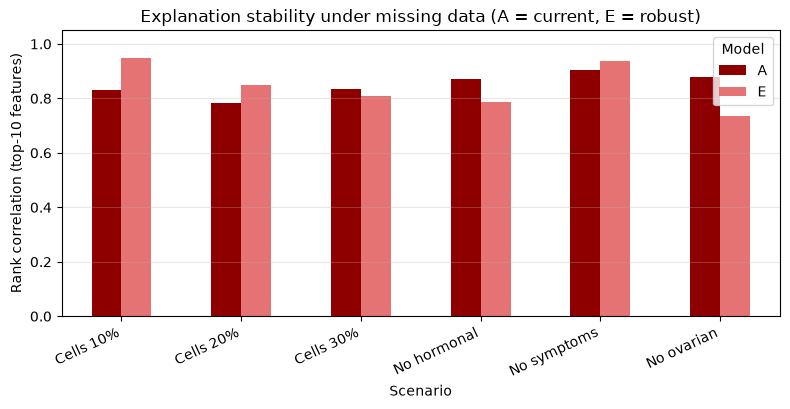

In [12]:
# ---------- C2: group-level importance, complete vs incomplete ----------
gtab = pd.DataFrame({f"{mk} complete": ref_grp[mk] for mk in ref_grp})
gdf = pd.DataFrame(grp_rows)
for mk in ref_grp:
    gtab[f"{mk} cells 30%"] = gdf[(gdf.Model == mk) & (gdf.Scenario == "Cells 30%")].groupby("Group").Importance.mean()
print("Group-level importance (drop in ROC-AUC when the whole group is shuffled). A = current model, E = robust model:")
display(gtab.round(4).sort_values("A complete", ascending=False))
gtab.round(4).to_csv(REPORTS / "C_group_importance.csv")

fig, ax = plt.subplots(figsize=(8, 4.2))
sel = stab[stab.Scenario.isin(stab_scen)].groupby(["Scenario", "Model"]).Spearman_top10.mean().unstack()[["A", "E"]].loc[stab_scen]
sel.plot(kind="bar", ax=ax, color=["#8E0000", "#E57373"]); ax.set_ylabel("Rank correlation (top-10 features)")
ax.set_ylim(0, 1.05); ax.set_title("Explanation stability under missing data (A = current, E = robust)")
plt.xticks(rotation=25, ha="right"); ax.grid(alpha=.3, axis="y"); plt.tight_layout()
plt.savefig(REPORTS / "C_explanation_stability.png", dpi=200); plt.show()

## Part D: Is the app's "Inconclusive" rule justified?
The app abstains when the score is within 35-65%, or fewer than 3 of 5 ovarian inputs, or fewer than 3 of 5
symptom inputs were given. Those cut-offs were design choices. Here they are tested on realistic partial
profiles: each patient lacks each clinical group independently with probability q, plus 3% random cell loss.
A good abstention rule should give **higher accuracy on the cases it decides**, at an acceptable coverage.

In [13]:
# ---------- D1: coverage vs accuracy of several abstention policies ----------
OV = GROUPS["Ovarian measurements"]
SY = ["Weight gain(Y/N)", "hair growth(Y/N)", "Skin darkening (Y/N)", "Hair loss(Y/N)", "Pimples(Y/N)"]
POLICIES = {
    "No abstention (threshold 0.5)": dict(band=None, ov=0, sy=0),
    "Input rules only (>=3 ovarian, >=3 symptom)": dict(band=None, ov=3, sy=3),
    "Score band 35-65% only": dict(band=(.35, .65), ov=0, sy=0),
    "CURRENT APP: band 35-65% + input rules": dict(band=(.35, .65), ov=3, sy=3),
    "Wider: band 30-70% + input rules": dict(band=(.30, .70), ov=3, sy=3),
}

def abstain_mask(prob, ov_got, sy_got, pol):
    a = (ov_got < pol["ov"]) | (sy_got < pol["sy"])
    if pol["band"]:
        a = a | ((prob >= pol["band"][0]) & (prob <= pol["band"][1]))
    return a

records = []
for fold_id, (Xte, yte) in fold_data.items():
    for q in (0.2, 0.4, 0.6):
        Xm = mask_random_groups(Xte, q, np.random.default_rng(77 + fold_id), cell_rate=0.03)
        ov_got, sy_got = Xm[OV].notna().sum(1).values, Xm[SY].notna().sum(1).values
        for k in ("A", DEPLOY):
            p = fitted[(fold_id, k)].predict_proba(prep(Xm, STRATS[k]["fill"]))[:, 1]
            records.append(pd.DataFrame(dict(Model=k, q=q, y=yte.values, p=p, ov=ov_got, sy=sy_got)))
rec = pd.concat(records, ignore_index=True)

out = []
for (mk, q), g in rec.groupby(["Model", "q"]):
    for pname, pol in POLICIES.items():
        ab = abstain_mask(g.p.values, g.ov.values, g.sy.values, pol)
        d = ~ab; pred = (g.p.values >= .5).astype(int)
        out.append(dict(Model=mk, Group_missing_prob=q, Policy=pname, Coverage=d.mean(),
                        Accuracy_on_decided=(pred[d] == g.y.values[d]).mean() if d.any() else np.nan,
                        Sensitivity_on_decided=pred[d & (g.y.values == 1)].mean() if (d & (g.y.values == 1)).any() else np.nan,
                        Accuracy_on_abstained_if_forced=(pred[ab] == g.y.values[ab]).mean() if ab.any() else np.nan))
pol_df = pd.DataFrame(out).round(3)
pol_df.to_csv(REPORTS / "D_abstention_policy_evaluation.csv", index=False)
for mk in ("A", DEPLOY):
    print(f"\nModel {mk}:")
    display(pol_df[pol_df.Model == mk].drop(columns="Model").set_index(["Group_missing_prob", "Policy"]))
print("Read it like this: if 'Accuracy_on_abstained_if_forced' is clearly LOWER than 'Accuracy_on_decided',"
      " the app was right to refuse those cases. 'Coverage' is the price paid.")


Model A:


Coverage  Accuracy_on_decided  Sensitivity_on_decided  Accuracy_on_abstained_if_forced
Group_missing_prob Policy                                                                                                                             
0.2                No abstention (threshold 0.5)                   1.000                0.873                   0.706                              NaN
                   Input rules only (>=3 ovarian, >=3 symptom)     0.630                0.906                   0.833                            0.818
                   Score band 35-65% only                          0.799                0.920                   0.736                            0.688
                   CURRENT APP: band 35-65% + input rules          0.496                0.952                   0.893                            0.796
                   Wider: band 30-70% + input rules                0.446                0.963                   0.903                            0.801
0.4                No abstention (threshold 0.5)                   1.000                0.822                   0.520                              NaN
                   Input rules only (>=3 ovarian, >=3 symptom)     0.347                0.907                   0.837                            0.777
                   Score band 35-65% only                          0.821                0.868                   0.513                            0.608
                   CURRENT APP: band 35-65% + input rules          0.274                0.960                   0.926                            0.769
                   Wider: band 30-70% + input rules                0.250                0.974                   0.940                            0.771
0.6                No abstention (threshold 0.5)                   1.000                0.768                   0.339                              NaN
                   Input rules only (>=3 ovarian, >=3 symptom)     0.169                0.885                   0.776                            0.744
                   Score band 35-65% only                          0.871                0.797                   0.264                            0.571
                   CURRENT APP: band 35-65% + input rules          0.137                0.946                   0.854                            0.740
                   Wider: band 30-70% + input rules                0.128                0.949                   0.853                            0.742


Model B:


Coverage  Accuracy_on_decided  Sensitivity_on_decided  Accuracy_on_abstained_if_forced
Group_missing_prob Policy                                                                                                                             
0.2                No abstention (threshold 0.5)                   1.000                0.873                   0.706                              NaN
                   Input rules only (>=3 ovarian, >=3 symptom)     0.630                0.906                   0.833                            0.818
                   Score band 35-65% only                          0.799                0.920                   0.737                            0.688
                   CURRENT APP: band 35-65% + input rules          0.496                0.952                   0.894                            0.796
                   Wider: band 30-70% + input rules                0.447                0.963                   0.903                            0.801
0.4                No abstention (threshold 0.5)                   1.000                0.822                   0.520                              NaN
                   Input rules only (>=3 ovarian, >=3 symptom)     0.347                0.907                   0.837                            0.777
                   Score band 35-65% only                          0.821                0.868                   0.513                            0.608
                   CURRENT APP: band 35-65% + input rules          0.274                0.960                   0.926                            0.769
                   Wider: band 30-70% + input rules                0.250                0.974                   0.940                            0.771
0.6                No abstention (threshold 0.5)                   1.000                0.769                   0.342                              NaN
                   Input rules only (>=3 ovarian, >=3 symptom)     0.169                0.885                   0.776                            0.745
                   Score band 35-65% only                          0.871                0.797                   0.264                            0.579
                   CURRENT APP: band 35-65% + input rules          0.137                0.946                   0.854                            0.741
                   Wider: band 30-70% + input rules                0.128                0.949                   0.853                            0.743

Read it like this: if 'Accuracy_on_abstained_if_forced' is clearly LOWER than 'Accuracy_on_decided', the app was right to refuse those cases. 'Coverage' is the price paid.


## Part E: Finalise. Save the deployed model, tables and a ready-to-paste summary

In [14]:
# ---------- E1: save the deployed model + results the app reads ----------
final_model, final_fill = final_models["E"] if DEPLOY == "E" else (final_models["A"][0], True)
backup = BACKUP_PATH
if not backup.exists():
    shutil.copy2(MODEL_PATH, backup)              # keep your original model safe
if DEPLOY == "E":
    joblib.dump(final_model, MODEL_PATH)
    print("Saved robust model (train-time masking) ->", MODEL_PATH.name, "| original kept as", backup.name)
else:
    print("Saved model file left unchanged (strategy B = same model + derived-value filling in the app).")

# held-out confirmation of what is actually deployed (complete + missing scenarios), derived-fill ON
dep_rows = []
for sc in ["Complete", "Cells 10%", "Cells 20%", "Cells 30%", "No physical", "No hormonal", "No menstrual",
           "No symptoms", "No ovarian", "No hormonal + ovarian (no lab, no scan)"]:
    Xm = SCENARIOS[sc](X_test, np.random.default_rng(999))
    p = final_model.predict_proba(prep(Xm, True))[:, 1]
    dep_rows.append(dict(Scenario=sc, **{k: v for k, v in metrics(y_test, p).items()
                                         if k in ("Accuracy", "Sensitivity", "Specificity", "ROC_AUC")}))
dep = pd.DataFrame(dep_rows).round(4)
dep.to_csv(REPORTS / "deployed_model_missing_results.csv", index=False)
print("\nHeld-out test result of the DEPLOYED configuration (what the app really does):")
display(dep)

meta = json.load(open(META_PATH))
meta.update(dict(deployed_strategy=DEPLOY, strategy_name=STRATS[DEPLOY]["name"],
                 derived_value_filling=True, train_time_masking=(DEPLOY == "E"),
                 derived_features=["BMI", "Waist:Hip Ratio", "FSH/LH"]))
json.dump(meta, open(META_PATH, "w"), indent=4)

# ---------- E2: plain-language summary for the report ----------
a_m, d_m = auc_tab.loc[miss_sc, "A"].mean(), auc_tab.loc[miss_sc, DEPLOY].mean()
summary = f"""
================ RESULTS SUMMARY (copy into the report) ================
1. Deployed model reproduces notebook result: {match} | test acc {m_saved['Accuracy']:.3f},
   sensitivity {m_saved['Sensitivity']:.3f} (95% CI {ci.loc['Sensitivity','CI 2.5%']:.2f}-{ci.loc['Sensitivity','CI 97.5%']:.2f}),
   ROC-AUC {m_saved['ROC_AUC']:.3f} (95% CI {ci.loc['ROC_AUC','CI 2.5%']:.2f}-{ci.loc['ROC_AUC','CI 97.5%']:.2f}).
2. Leakage test: shuffled-label AUC {np.mean(perm_scores):.2f} (real {real:.2f}).
3. Missing-data handling: mean ROC-AUC over {len(miss_sc)} incomplete-data scenarios rises from
   {a_m:.3f} (median imputation) to {d_m:.3f} (strategy {DEPLOY}); complete-data AUC {cplt['A']:.3f} -> {cplt[DEPLOY]:.3f}.
4. Explanations under 30% missing cells: Rank correlation (top-10 features) vs complete-data ranking
   A = {stab_summary.loc[('A','Cells 30%'),'Spearman_top10']:.2f}, E = {stab_summary.loc[('E','Cells 30%'),'Spearman_top10']:.2f}.
5. Abstention rule: see Part D table (accuracy on decided vs forced).
Limitations: 541 records, one dataset, one hospital; features overlap with diagnostic criteria
(follicle counts, AMH, LH/FSH); missingness is SIMULATED (MCAR and group-block), not observed.
==========================================================================
"""
print(summary)
(REPORTS / "results_summary.txt").write_text(summary, encoding="utf-8")
print("Files written to", REPORTS)

Saved model file left unchanged (strategy B = same model + derived-value filling in the app).

Held-out test result of the DEPLOYED configuration (what the app really does):


,Scenario,Accuracy,Sensitivity,Specificity,ROC_AUC
0,Complete,0.9083,0.8333,0.9452,0.9425
1,Cells 10%,0.8899,0.7778,0.9452,0.9323
2,Cells 20%,0.8807,0.7222,0.9589,0.9115
3,Cells 30%,0.8440,0.5833,0.9726,0.8942
4,No physical,0.8991,0.8333,0.9315,0.9509
5,No hormonal,0.9083,0.8333,0.9452,0.9287
6,No menstrual,0.9266,0.8333,0.9726,0.9374
7,No symptoms,0.8349,0.5278,0.9863,0.9024
8,No ovarian,0.8073,0.5556,0.9315,0.8857
9,"No hormonal + ovarian (no lab, no scan)",0.8257,0.5833,0.9452,0.8697



================ RESULTS SUMMARY (copy into the report) ================
1. Deployed model reproduces notebook result: True | test acc 0.908,
   sensitivity 0.833 (95% CI 0.70-0.94),
   ROC-AUC 0.943 (95% CI 0.88-0.99).
2. Leakage test: shuffled-label AUC 0.50 (real 0.96).
3. Missing-data handling: mean ROC-AUC over 12 incomplete-data scenarios rises from
   0.916 (median imputation) to 0.916 (strategy B); complete-data AUC 0.960 -> 0.960.
4. Explanations under 30% missing cells: Rank correlation (top-10 features) vs complete-data ranking
   A = 0.84, E = 0.81.
5. Abstention rule: see Part D table (accuracy on decided vs forced).
Limitations: 541 records, one dataset, one hospital; features overlap with diagnostic criteria
(follicle counts, AMH, LH/FSH); missingness is SIMULATED (MCAR and group-block), not observed.

Files written to C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports
